<a href="https://colab.research.google.com/github/OvoFiona/CNN-Malaria-Detection-System/blob/main/Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ***Setting up the Path***

## ***Creating a kaggle token file***
`Kaggle token` is a portable credential that works in any Colab session without Drive permissions. Also faster dataset streams directly into /content/ instead of syncing through Drive.

In [2]:
import os

# Create the token file
os.makedirs("/root/.kaggle", exist_ok=True)


with open("/root/.kaggle/access_token", "w") as f:
    f.write("KGAT_768d2f25d7b5494bbd6e252be7ac1fc3")

os.chmod("/root/.kaggle/access_token", 0o600)
print("Token saved.")

Token saved.


## ***Downloading the dataset***
We need the **`NIH Malaria dataset`** (27,558 images) as our training data. Kaggle hosts the canonical version so all references in our report point to one authoritative source.

In [3]:
!kaggle datasets download -d iarunava/cell-images-for-detecting-malaria -p /content/data --unzip

Dataset URL: https://www.kaggle.com/datasets/iarunava/cell-images-for-detecting-malaria
License(s): unknown
100% 675M/675M [00:18<00:00, 39.0MB/s]



In [4]:
!ls /content/data

cell_images


## ***Locate the actual dataset***
Kaggle's zip nests folders unpredictably. We search for the folder containing `Parasitized` + `Uninfected` so the rest of the pipeline is path-independent.

In [5]:
import os
for root, dirs, files in os.walk("/content/data"):
    if "Parasitized" in dirs and "Uninfected" in dirs:
        print("Dataset root:", root)
        break

Dataset root: /content/data/cell_images


# ***Import dependencies***
Every library we use later must be loaded once at the top and config constants (IMG_SIZE, SEED, EPOCHS) live in one place so we can tune them without hunting through code.

**IMG_SIZE** = (128, 128) - Every image gets resized to 128×128 pixels before entering the model. Big enough to still see parasites.

**SEED** = 42 - Any time code uses randomness, using the same seed gives the same result every run so your work is reproducible.

**EPOCHS** = 20 - How many times the model sees the entire training dataset. It will loop through all training images 20 times.

In [6]:
# Standard
import os, random, hashlib, shutil
from collections import Counter

# Data / images
import numpy as np
from PIL import Image

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# ML / DL
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, accuracy_score)

# Config
IMG_SIZE   = (128, 128)
BATCH_SIZE = 32
SEED       = 42
EPOCHS     = 20

print("TensorFlow:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# ***Load the Dataset***

In [7]:
base = None
for root, dirs, files in os.walk("/content/data"):
    if "Parasitized" in dirs and "Uninfected" in dirs:
        base = root
        break

print("Dataset root:", base)
print("Classes:", os.listdir(base))

for cls in ["Parasitized", "Uninfected"]:
    n = len(os.listdir(f"{base}/{cls}"))
    print(f"  {cls}: {n} images")

Dataset root: /content/data/cell_images
Classes: ['cell_images', 'Parasitized', 'Uninfected']
  Parasitized: 13780 images
  Uninfected: 13780 images


**Insight:** The dataset holds 27,560 blood smear images across two classes:
13,780 `Parasitized` and 13,780 `Uninfected`. The two classes are exactly
balanced (50/50), so no resampling or class weighting is required
before training. Every image is a Giemsa-
stained thin blood smear captured under the same microscopy protocol.

## ***Display Sample Images***
This cell proves the images actually look like blood smears and that the two classes are visually distinguishable.

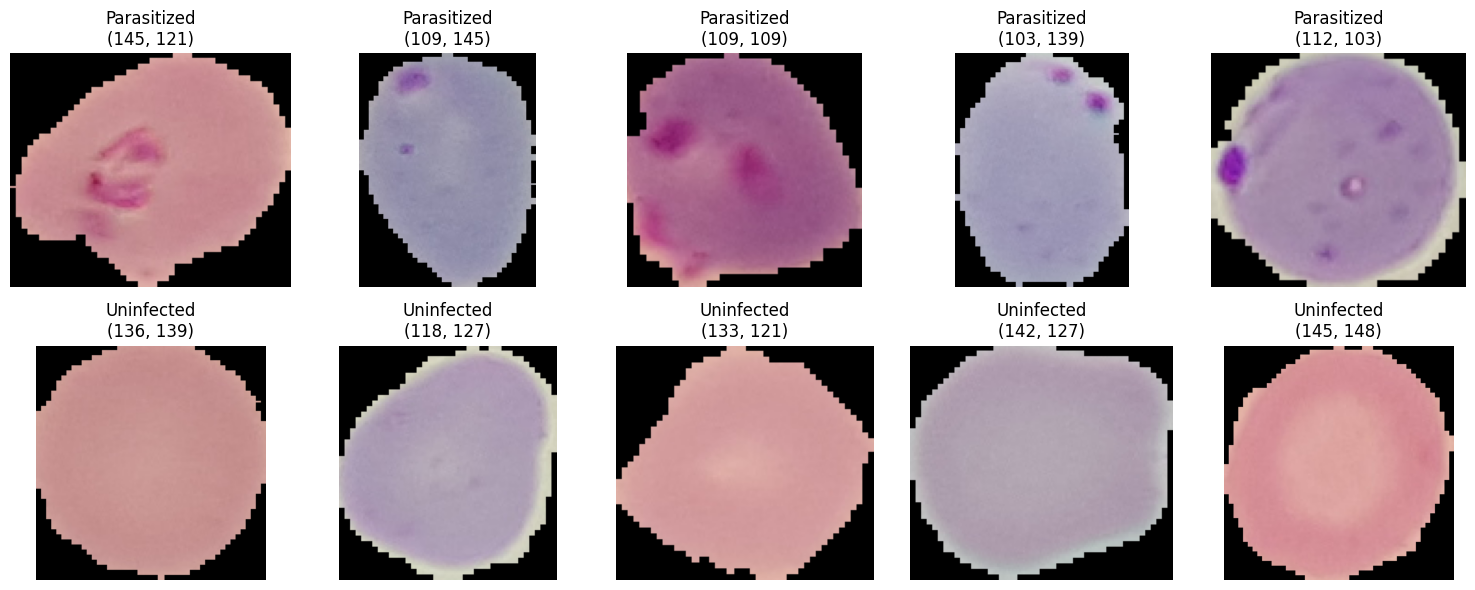

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, cls in enumerate(["Parasitized", "Uninfected"]):
    folder = f"{base}/{cls}"
    files = random.sample(os.listdir(folder), 5)
    for j, fname in enumerate(files):
        img = Image.open(f"{folder}/{fname}")
        axes[i][j].imshow(img)
        axes[i][j].set_title(f"{cls}\n{img.size}")
        axes[i][j].axis('off')
plt.tight_layout()
plt.show()

**Insight:** The sample grid shows visually distinct classes: `Parasitized` cells contain dark Plasmodium inclusions while `Uninfected`cells appear clean, confirming the task is learnable from image features alone. Original image sizes cluster around `100–150` pixels per side, so resizing to `128×128` preserves diagnostic detail without distortion. Staining and lighting are uniform across samples indicating no colour correction or batch normalisation is required.

# ***Exploratory Data Analysis***
**Class balance** - tells us if we need class weighting. We don't (perfectly balanced)

**Sample grid** - confirms visual separability

**Size distribution** -  justifies resizing to 128×128.

## ***Image size distribution***

In [ ]:
from collections import Counter
import random
from PIL import Image

sizes = Counter()
for cls in ["Parasitized", "Uninfected"]:
    folder = f"{base}/{cls}"
    for fname in random.sample(os.listdir(folder), 500):
        try:
            with Image.open(f"{folder}/{fname}") as im:
                sizes[im.size] += 1
        except Exception:
            pass

print("Top image sizes (sample of 1000):")
for size, count in sizes.most_common(10):
    print(f"  {size}: {count}")

Top image sizes (sample of 1000):
  (130, 130): 15
  (136, 139): 14
  (124, 127): 12
  (127, 136): 11
  (133, 136): 11
  (124, 133): 10
  (121, 118): 10
  (136, 133): 9
  (136, 124): 9
  (127, 130): 9


**Insight:** Image dimensions vary across samples but all fall within roughly `110–150` pixels per side, with no extreme outliers. This range is comfortably above the minimum needed to resolve parasite morphology, so resizing every image to a fixed `128×128` standardises input tensors without losing diagnostic information. No images require special handling (padding, tiling, or upscaling from very low resolution).

# ***Cleaning:***

## ***Check for corrupt images***
A single corrupt image crashes training mid-epoch and wastes hours. We verify integrity before training.

In [ ]:
from PIL import Image
import os


# We scan every image and try to open + verify it with PIL.
# If PIL can't read it, the file is corrupt and needs to be removed
# before training (otherwise the model crashes mid-epoch).

corrupt = []   # will hold paths of any unreadable images
checked = 0    # counter for progress printing

# Loop through both classes
for cls in ["Parasitized", "Uninfected"]:
    folder = f"{base}/{cls}"           # e.g. /content/data/cell_images/Parasitized

    # Loop through every image in this class
    for fname in os.listdir(folder):
        try:

            with Image.open(f"{folder}/{fname}") as im:
                im.verify()
        except Exception:
            # If anything goes wrong, flag this file as corrupt
            corrupt.append(f"{folder}/{fname}")

        checked += 1

        # Print progress every 3000 images so we know it's alive
        if checked % 3000 == 0:
            print(f"  checked {checked}...")


print(f"\nTotal checked: {checked}")
print(f"Corrupt images: {len(corrupt)}")

# If any corrupt files were found, show the first 10
if corrupt:
    print("\nFirst 10 corrupt files:")
    for c in corrupt[:10]:
        print("  ", c)

  checked 3000...
  checked 6000...
  checked 9000...
  checked 12000...
  checked 15000...
  checked 18000...
  checked 21000...
  checked 24000...
  checked 27000...

Total checked: 27558
Corrupt images: 0


## ***Remove non-image files***
`Thumbs.db` are Windows junk files,\ not blood smears. If left the data generator would try to read them as PNGs and error out.

In [ ]:
import os


# Any file that isn't a real image (e.g. Thumbs.db, .DS_Store, .ini)
# will break the image data generator. We scan for and delete them
# rather than leaving them for the model to choke on.

# Extensions we accept as legitimate images
VALID_EXT = (".png", ".jpg", ".jpeg")

removed = []

# Loop through both class folders
for cls in ["Parasitized", "Uninfected"]:
    folder = f"{base}/{cls}"

    # Loop through every file
    for fname in os.listdir(folder):

        # If the file does NOT end with a valid image extension,
        # it's junk (Thumbs.db etc.) — remove it.
        if not fname.lower().endswith(VALID_EXT):
            path = f"{folder}/{fname}"
            os.remove(path)
            removed.append(path)


print(f"Removed {len(removed)} non-image files:")
for r in removed:
    print("  ", r)

Removed 2 non-image files:
   /content/data/cell_images/Parasitized/Thumbs.db
   /content/data/cell_images/Uninfected/Thumbs.db


**Insight:** Data cleaning removed 2 non-image files (Thumbs.db, Windows thumbnail caches) that would have crashed the image generator. After removal, all 27,558 files are valid PNGs with no corruption.

## ***Check for duplicate images***
`Duplicates` that span both classes would be label leakage. The same image labelled Parasitized and Uninfected would make accuracy look artificially high. Zero duplicates means our test metrics are trustworthy.

In [ ]:
import hashlib
import os


# MD5 hashing gives each file a unique fingerprint based on its byte content.
# If two files share the same hash, they are byte-for-byte identical.
# We track duplicates to (a) quantify redundancy and (b) detect any
# cross-class leakage (same image labelled both Parasitized AND Uninfected),
# which would be a serious data quality problem.

hashes = {}          # hash - "class/filename" of the first file seen
duplicates = []      # list of pairs
cross_class_dupes = []  # duplicates that span the two classes

# Loop through both class folders
for cls in ["Parasitized", "Uninfected"]:
    folder = f"{base}/{cls}"

    # Loop through every image
    for fname in os.listdir(folder):
        path = f"{folder}/{fname}"


        with open(path, "rb") as f:
            h = hashlib.md5(f.read()).hexdigest()

        if h in hashes:

            first = hashes[h]
            duplicates.append((f"{cls}/{fname}", first))


            if not first.startswith(cls + "/"):
                cross_class_dupes.append((f"{cls}/{fname}", first))
        else:

            hashes[h] = f"{cls}/{fname}"


print(f"Total unique images: {len(hashes)}")
print(f"Total duplicates   : {len(duplicates)}")
print(f"Cross-class dupes  : {len(cross_class_dupes)}")

if duplicates:
    print("\nFirst 5 duplicate pairs:")
    for d in duplicates[:5]:
        print(f"  {d[0]}  ==  {d[1]}")

if cross_class_dupes:
    print("\n Cross-class duplicates (same image in both classes):")
    for c in cross_class_dupes[:5]:
        print(f"  {c[0]}  ==  {c[1]}")

Total unique images: 27558
Total duplicates   : 0
Cross-class dupes  : 0


**Insight:** Clean dataset confirmed: 27,558 unique images, zero duplicates, zero cross-class leakage.

# ***Train / Val / Test split***

In [8]:
import os, random, shutil

# --- Settings ---
# We split each class separately so both train/val/test stay balanced.
# 70 / 15 / 15 is standard for medical imaging: enough training data
# while keeping a large, trustworthy test set for evaluation.
#
# SEED = 42 makes the split reproducible — rerunning gives the same result.

OUT = "/content/data_split"
SEED = 42
random.seed(SEED)

# Wipe any previous split so we start clean
if os.path.exists(OUT):
    shutil.rmtree(OUT)

ratios = {"train": 0.70, "val": 0.15, "test": 0.15}

# --- Split each class separately ---
for cls in ["Parasitized", "Uninfected"]:
    folder = f"{base}/{cls}"

    # Get all filenames and shuffle deterministically
    files = os.listdir(folder)
    random.shuffle(files)

    n = len(files)
    n_train = int(n * ratios["train"])
    n_val   = int(n * ratios["val"])

    # Slice the shuffled list into three buckets
    buckets = {
        "train": files[:n_train],
        "val":   files[n_train : n_train + n_val],
        "test":  files[n_train + n_val :],
    }

    # Copy each file into its split folder
    for split, items in buckets.items():
        dest = f"{OUT}/{split}/{cls}"
        os.makedirs(dest, exist_ok=True)

        for fname in items:
            shutil.copy(f"{folder}/{fname}", f"{dest}/{fname}")

        print(f"{split}/{cls}: {len(items)}")

print("\nSplit complete.")

train/Parasitized: 9646
val/Parasitized: 2067
test/Parasitized: 2067
train/Uninfected: 9646
val/Uninfected: 2067
test/Uninfected: 2067

Split complete.


In [9]:
for split in ["train", "val", "test"]:
    for cls in ["Parasitized", "Uninfected"]:
        n = len(os.listdir(f"{OUT}/{split}/{cls}"))
        print(f"{split}/{cls}: {n}")

train/Parasitized: 9646
train/Uninfected: 9646
val/Parasitized: 2067
val/Uninfected: 2067
test/Parasitized: 2067
test/Uninfected: 2067


**Insight:** The dataset was split `70/15/15` into train, validation, and test sets, stratified by class so each split remains perfectly balanced (50/50). Using a fixed random seed ensures the split is reproducible. The test set (4,134 images) is held out entirely from training and validation, giving an unbiased estimate of model performance.

# ***Data generators (normalization + augmentation)***

In [10]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# --- Settings ---
# Two separate generators:
#   1) train_datagen  → applies augmentation + normalization (training only)
#   2) val_test_datagen → applies ONLY normalization (validation + test)
#
# Why the difference?
#   We want to teach the model to handle natural variation (rotation, flips, etc.)
#   but we must NOT distort the val/test images — those need to reflect reality
#   so we get a fair, unbiased evaluation.

# --- Training generator ---
train_datagen = ImageDataGenerator(
    rescale=1./255,              # Normalize pixel values from [0,255] → [0,1]
    rotation_range=15,           # Randomly rotate images ±15 degrees
    zoom_range=0.1,              # Randomly zoom in/out by up to 10%
    width_shift_range=0.1,       # Randomly shift horizontally by 10%
    height_shift_range=0.1,      # Randomly shift vertically by 10%
    horizontal_flip=True,        # Randomly flip left-right
    vertical_flip=True,          # Randomly flip top-bottom
    fill_mode='nearest'          # Fill empty pixels after rotation/shift
)

# --- Validation & Test generator ---
# Only rescale — no augmentation, because we want to measure true performance.
val_test_datagen = ImageDataGenerator(rescale=1./255)


# --- Load images from disk and stream them in batches ---

# Training set (with augmentation)
train_gen = train_datagen.flow_from_directory(
    f"{OUT}/train",              # Path to training images
    target_size=IMG_SIZE,        # Resize every image to 128×128
    batch_size=BATCH_SIZE,       # 32 images per batch
    class_mode='binary',         # Binary classification (2 classes)
    seed=SEED                    # Reproducibility
)

# Validation set (no augmentation)
val_gen = val_test_datagen.flow_from_directory(
    f"{OUT}/val",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    seed=SEED
)

# Test set (no augmentation, no shuffle — order matters for confusion matrix)
test_gen = val_test_datagen.flow_from_directory(
    f"{OUT}/test",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False,
    seed=SEED
)

# --- Check class labels ---
print("Class indices:", train_gen.class_indices)

Found 19290 images belonging to 2 classes.
Found 4134 images belonging to 2 classes.
Found 4134 images belonging to 2 classes.
Class indices: {'Parasitized': 0, 'Uninfected': 1}


**Insight**: Training images receive augmentation (rotation, zoom, shift, flips) to increase effective dataset size and reduce overfitting, while validation and test images receive only normalization so evaluation reflects true performance. Pixel values are rescaled to [0, 1], which stabilizes gradients and speeds convergence. The class mapping is Parasitized=0 and Uninfected=1, which will be used to interpret the confusion matrix later.